In [1]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_11/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 11.3. N-HiTS: длинный горизонт и итоговое сравнение

В N-BEATS каждый блок выдаёт все `h` точек горизонта в полном разрешении. На сутках (`h=96`) это нормально.
А если прогноз нужен на неделю вперёд — `h=720` точек на 15-минутной сетке?
Выходной слой каждого блока растёт пропорционально `h`, модель тяжелеет, а прогноз может «дрожать».

Авторы N-HiTS называют эти две проблемы прямо: **вычислительная сложность** и **волатильность прогноза**
(forecast volatility). В статье (рис. 1) у полносвязной модели с ростом горизонта до 1000 точек одновременно
растут число параметров, время шага обучения и MAE. Причина общая: у модели слишком много свободы на выходе.
Каждую из $H$ точек сеть предсказывает независимым выходом. Соседние точки прогноза почти одинаковы, но сеть
об этом не знает и должна выучить гладкость из данных.

**N-HiTS** (2022) — N-BEATS, в котором каждый стек работает в своём временном разрешении.
Гладкость прогноза в нём задана архитектурой, а не выучивается.

Разбираем:
- две идеи N-HiTS: пулинг входа и иерархическую интерполяцию прогноза;
- N-BEATS и N-HiTS на горизонте 720 точек: параметры, время, качество;
- разложение прогноза N-HiTS по частотам;
- итоговое сравнение всех моделей семинара.

In [2]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasetsforecast.long_horizon import LongHorizon
from neuralforecast import NeuralForecast
from neuralforecast.models import NBEATS, NHITS, DLinear
from neuralforecast.tsdataset import TimeSeriesDataset
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mse

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=False, enable_model_summary=False, logger=False)

/Users/a.p.chikov/PycharmProjects/Временные ряды/Семинары/11/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


In [3]:
def score(cv):
    """MAE и MSE каждой модели, усреднённые по рядам и окнам кросс-валидации."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, mse], models=models)
    return res.groupby("metric")[models].mean().T.round(3).sort_values("mae")


def n_params(model):
    return sum(p.numel() for p in model.parameters())

## Данные: ETTm2

Тот же бенчмарк: 7 рядов трансформатора, шаг 15 минут, ряды уже стандартизованы.
Горизонт 720 точек — это 7.5 суток. Окно истории — тоже 720 точек: в протоколе долгосрочного прогноза
окно часто не длиннее горизонта, а обучение так заметно дешевле.

Тест — 5 последних отрезков по 720 точек (≈ 37 суток), модели обучаются один раз на всём, что раньше.

In [4]:
Y_df, _, _ = LongHorizon.load(directory="../data", group="ETTm2")
Y_df["ds"] = pd.to_datetime(Y_df["ds"])
print(Y_df.shape, Y_df["unique_id"].nunique(), "рядов")

(403200, 3) 7 рядов


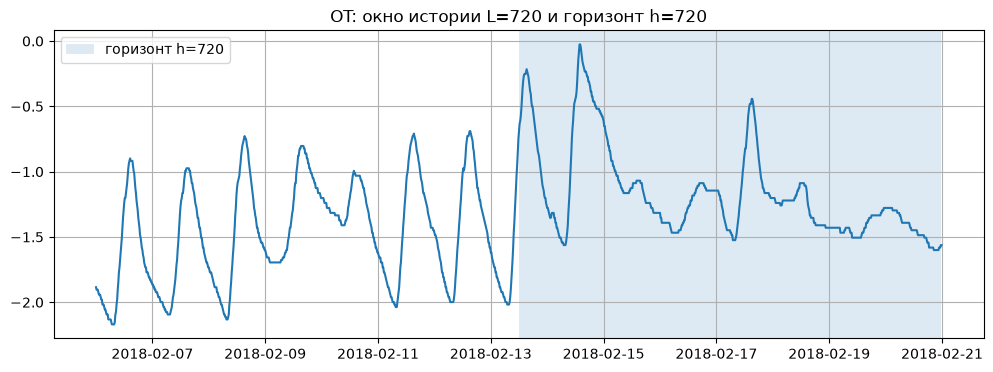

In [5]:
H = 720
L = 720
N_WINDOWS = 5
MAX_STEPS = 300  # больше шагов на ETTm2 — переобучение глубоких моделей
LR = 1e-3

ot = Y_df[Y_df["unique_id"] == "OT"].set_index("ds")["y"]
plt.plot(ot.iloc[-H - L :])
plt.axvspan(ot.index[-H], ot.index[-1], alpha=0.15, label=f"горизонт h={H}")
plt.title(f"OT: окно истории L={L} и горизонт h={H}")
plt.legend();

## 1. Идея N-HiTS

Архитектура та же, что у N-BEATS: блоки, backcast / forecast, двойные остаточные связи, сумма прогнозов блоков.
Меняются вход и выход блока: у каждого стека своё временное разрешение.

### Пулинг входа

Перед MLP окно сжимается `MaxPool1d` с ядром `k` (`n_pool_kernel_size`): из $L$ точек остаётся $L/k$.
Первый стек видит грубую картинку — только медленную динамику, последний — окно целиком.
Меньше входов → меньше весов в первом слое.

Для блока $\ell$ с входом $\mathbf{y}_{t-L:t,\ell}$ (остаток после предыдущих блоков) в статье:

$$
\mathbf{y}^{(p)}_{t-L:t,\ell} = \mathrm{MaxPool}\left(\mathbf{y}_{t-L:t,\ell},\, k_\ell\right), \qquad
\mathbf{h}_\ell = \mathrm{MLP}_\ell\left(\mathbf{y}^{(p)}_{t-L:t,\ell}\right), \qquad
\boldsymbol\theta^f_\ell = \mathrm{LINEAR}^f(\mathbf{h}_\ell),\;\; \boldsymbol\theta^b_\ell = \mathrm{LINEAR}^b(\mathbf{h}_\ell).
$$

Авторы называют это **multi-rate sampling**: каждый блок видит ряд со своей частотой дискретизации.
Окно по-прежнему покрывает все $L$ шагов истории (receptive field не сужается), просто грубее.
Меньше весов — меньше памяти, вычислений и склонности к переобучению.

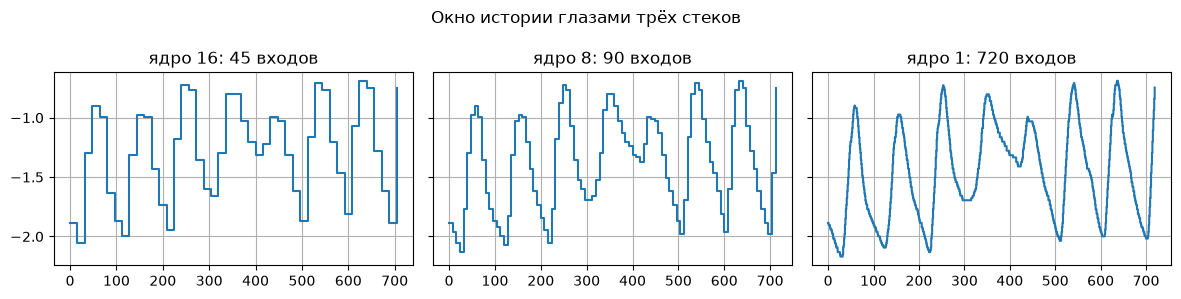

In [6]:
POOL = [16, 8, 1]  # n_pool_kernel_size
DOWN = [24, 12, 1]  # n_freq_downsample

window = torch.tensor(ot.iloc[-H - L : -H].to_numpy(), dtype=torch.float32)
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, k in zip(axes, POOL):
    pooled = F.max_pool1d(window[None, None], kernel_size=k, ceil_mode=True)[0, 0]
    ax.step(np.arange(len(pooled)) * k, pooled, where="post")
    ax.set_title(f"ядро {k}: {len(pooled)} входов")
fig.suptitle("Окно истории глазами трёх стеков")
fig.tight_layout()

Почему максимум, а не среднее? В статье (прил. G, табл. A6) MaxPool в большинстве случаев лучше AvgPool: на `h=720`
в среднем по пяти датасетам MSE ниже на 15.2%, MAE — на 8.3%. Одно из объяснений видно на картинке:
среднее срезает пики суточного цикла, а максимум сохраняет его амплитуду.

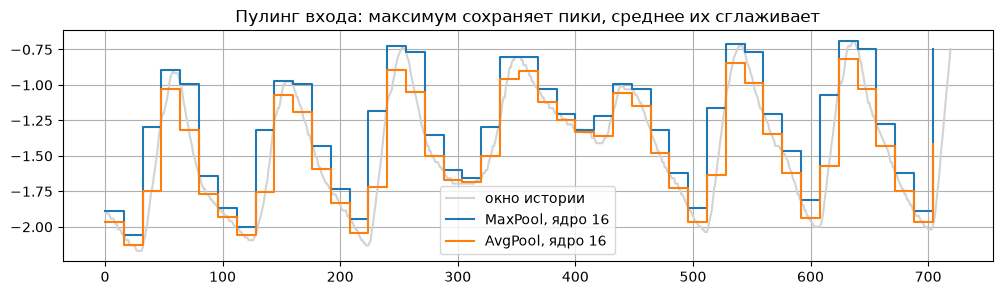

In [7]:
k = POOL[0]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(window, color="lightgrey", label="окно истории")
for name, pool in [("MaxPool", F.max_pool1d), ("AvgPool", F.avg_pool1d)]:
    pooled = pool(window[None, None], kernel_size=k, ceil_mode=True)[0, 0]
    ax.step(np.arange(len(pooled)) * k, pooled, where="post", label=f"{name}, ядро {k}")
ax.set_title("Пулинг входа: максимум сохраняет пики, среднее их сглаживает")
ax.legend();

### Иерархическая интерполяция выхода

Блок N-BEATS выдаёт $H$ чисел прогноза. Блок N-HiTS выдаёт только $H/r$ **узлов** (`n_freq_downsample` = $r$)
и линейно интерполирует их до $H$ точек. Узлов мало → прогноз стека гладкий по построению: стек с $r=24$
физически не может нарисовать колебание быстрее 6 часов.

Формально (в статье): узлы $\boldsymbol\theta^f_\ell$ стоят на равномерной сетке с шагом $r$, прогноз
в точке $\tau$ между соседними узлами $t_1 \le \tau < t_2$ —

$$
\hat y_{\tau,\ell} = \theta[t_1] + \frac{\theta[t_2] - \theta[t_1]}{t_2 - t_1}\,(\tau - t_1).
$$

Это обычная кусочно-линейная функция. Обучаются только значения в узлах, интерполяция фиксирована.
В статье «выразительность» задана долей $r_\ell$: $|\boldsymbol\theta^f_\ell| = \lceil r_\ell H\rceil$.
В `neuralforecast` параметр обратный: `n_freq_downsample` $= 1/r_\ell$, узлов `max(H // r, 1)`.
В статье интерполируется и backcast, в `neuralforecast` — только прогноз: backcast выдаётся во всех $L$ точках.

Не теряем ли мы так выразительность? В статье (прил. A) доказана теорема об аппроксимации: если прогноз
гладко зависит от истории, то кусочно-постоянных или кусочно-линейных функций на всё более мелких сетках
(как в вейвлетах Хаара) хватает, чтобы приблизить его сколь угодно точно.

Что можно нарисовать с разным числом узлов — на настоящем будущем ряда (узлы — средние по отрезкам):

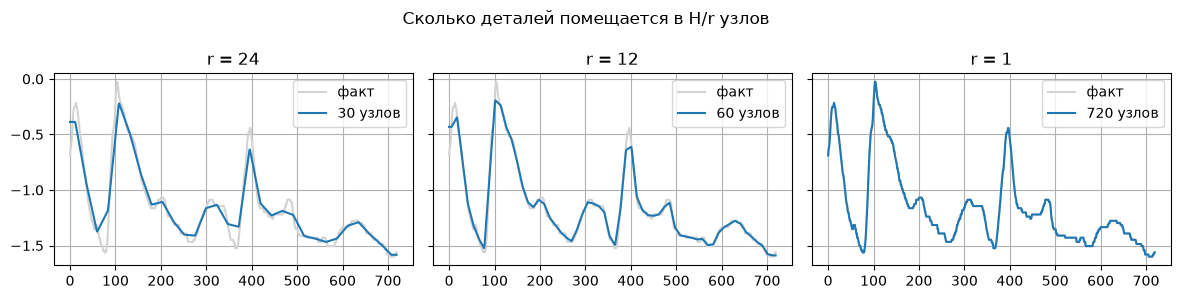

In [8]:
future = torch.tensor(ot.iloc[-H:].to_numpy(), dtype=torch.float32)
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, r in zip(axes, DOWN):
    knots = F.avg_pool1d(future[None, None], kernel_size=r)  # H / r узлов
    smooth = F.interpolate(knots, size=H, mode="linear")[0, 0]  # как в блоке N-HiTS
    ax.plot(future, color="lightgrey", label="факт")
    ax.plot(smooth, label=f"{knots.shape[-1]} узлов")
    ax.set_title(f"r = {r}")
    ax.legend()
fig.suptitle("Сколько деталей помещается в H/r узлов")
fig.tight_layout()

Способ интерполяции — тоже выбор (`interpolation_mode`). В статье (прил. G, табл. A7) линейная
интерполяция лучше «ближайшего соседа» (ступенек) до 15.8% по MSE на `h=720`. Между линейной
и кубической явного победителя нет, и авторы выбрали линейную как более дешёвую.
Сравним три способа на тех же 30 узлах (видны первые трое суток, MAE — по всему горизонту):

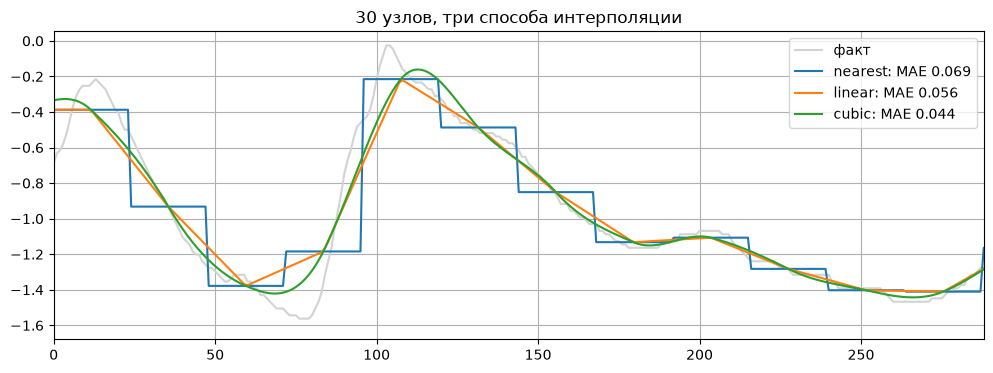

In [9]:
r = DOWN[0]
knots = F.avg_pool1d(future[None, None], kernel_size=r)
curves = {
    "nearest": F.interpolate(knots, size=H, mode="nearest")[0, 0],
    "linear": F.interpolate(knots, size=H, mode="linear")[0, 0],
    "cubic": F.interpolate(knots[:, None], size=(1, H), mode="bicubic")[0, 0, 0],  # так cubic устроен в NHITS
}
plt.plot(future, color="lightgrey", label="факт")
for name, curve in curves.items():
    plt.plot(curve, label=f"{name}: MAE {(curve - future).abs().mean():.3f}")
plt.xlim(0, 3 * 96)
plt.title(f"{H // r} узлов, три способа интерполяции")
plt.legend();

Ступеньки дают разрывы, которых в реальном ряде нет. Кубическая кривая здесь ближе всего к факту, но это
идеальный случай: узлы взяты из настоящего будущего. Когда узлы предсказывает сеть, кубика может
«перелетать» между узлами, и в статье её выигрыш у линейной не устойчив.

Стеки идут от грубого к детальному: первый рисует медленную динамику, следующие добавляют то, что осталось.
Это разложение по частотам вместо «тренд + сезонность» интерпретируемого N-BEATS. Как и в N-BEATS, блоки
связаны двойными остаточными связями:

$$
\mathbf{y}_{t-L:t,\ell+1} = \mathbf{y}_{t-L:t,\ell} - \tilde{\mathbf{y}}_{t-L:t,\ell}, \qquad
\hat{\mathbf{y}}_{t+1:t+H} = \sum_\ell \hat{\mathbf{y}}_{t+1:t+H,\ell}.
$$

Каждый следующий блок получает историю, из которой уже вычтено то, что объяснили предыдущие.

Порядок «от грубого к детальному» (top-down) — осознанный выбор. В статье (табл. A8) его сравнили
с обратным (bottom-up: сначала мелкие детали, потом медленная динамика): top-down в среднем лучше на 4.6%
по MAE и на 7.5% по MSE. Это совпадает с привычной практикой: сначала моделируют тренд и сезонность,
потом остатки.

Выигрыш в размере: на выходе блока $L + H$ чисел у N-BEATS против $L + H/r$ у N-HiTS, а на входе
$L$ против $L/k$. Таблица ниже — для блоков generic N-BEATS (`identity`).

In [10]:
pd.DataFrame(
    {
        "вход MLP": [L] * 3 + [L // k for k in POOL],
        "выход MLP (backcast + forecast)": [L + H] * 3 + [L + H // r for r in DOWN],
    },
    index=[f"N-BEATS generic блок {i}" for i in (1, 2, 3)]
    + [f"N-HiTS стек {i} (k={k}, r={r})" for i, (k, r) in enumerate(zip(POOL, DOWN), 1)],
)

,вход MLP,выход MLP (backcast + forecast)
N-BEATS generic блок 1,720,1440
N-BEATS generic блок 2,720,1440
N-BEATS generic блок 3,720,1440
"N-HiTS стек 1 (k=16, r=24)",45,750
"N-HiTS стек 2 (k=8, r=12)",90,780
"N-HiTS стек 3 (k=1, r=1)",720,1440


Параметры `NHITS`:

| идея | параметр | по умолчанию | для длинного горизонта (как выше) |
|---|---|---|---|
| пулинг входа | `n_pool_kernel_size` | `[2, 2, 1]` | `[16, 8, 1]` |
| число узлов $H/r$ | `n_freq_downsample` | `[4, 2, 1]` | `[24, 12, 1]` |
| способ интерполяции | `interpolation_mode` | `"linear"` | |
| способ пулинга | `pooling_mode` | `"MaxPool1d"` | |

Наши `[16, 8, 1]` и `[24, 12, 1]` взяты из сетки статьи (табл. A3). Авторы перебирали всего пять вариантов
каждого параметра: например, для узлов `[168, 24, 1]` (неделя и сутки на часовых данных), `[24, 12, 1]`,
`[180, 60, 1]`, `[40, 20, 1]`, `[64, 8, 1]`. Часть вариантов подобрана под сезонности данных, часть растёт
экспоненциально.

Экспоненциальный рост здесь не случаен. Если узлы стеков образуют геометрическую прогрессию, суммарный
размер выходов растёт как $O\big(H(1-r^B)/(1-r)\big)$ — сумма геометрической прогрессии, в ней доминирует
стек с полным разрешением, а грубые стеки почти ничего не добавляют. У generic N-BEATS — $O(HB)$, у интерпретируемого — $O(H^2 B)$ (статья, табл. A2): число
гармоник в его сезонном базисе растёт с горизонтом.

Посмотрим, как число параметров растёт с горизонтом (модели только создаём, не обучаем; окно $L = H$).
В том же разрезе это показано в статье на рис. 1a и 4b.

In [11]:
sizes = {}
for h in [96, 192, 336, 720]:
    kw = dict(h=h, input_size=h, random_seed=SEED, **TRAINER_KW)
    sizes[f"h={h}"] = {
        "N-BEATS generic (3 × identity)": n_params(NBEATS(stack_types=["identity"] * 3, **kw)),
        "N-BEATS по умолчанию (identity + trend + seasonality)": n_params(NBEATS(**kw)),
        "N-HiTS по умолчанию": n_params(NHITS(**kw)),
        "N-HiTS 24-12-1": n_params(NHITS(n_pool_kernel_size=POOL, n_freq_downsample=DOWN, **kw)),
    }
(pd.DataFrame(sizes) / 1e6).round(2)

,h=96,h=192,h=336,h=720
N-BEATS generic (3 × identity),2.81,3.25,3.92,5.69
N-BEATS по умолчанию (identity + trend + seasonality),2.85,3.40,4.37,7.76
N-HiTS по умолчанию,2.70,3.03,3.53,4.86
N-HiTS 24-12-1,2.63,2.89,3.28,4.33


- На `h=96` все модели одного размера: основную часть весов дают скрытые слои 512×512.
- К `h=720` N-BEATS по умолчанию вырастает почти втрое, а N-HiTS `24-12-1` — менее чем в 1.7 раза.
- Самый тяжёлый блок N-BEATS по умолчанию — сезонный: на `h=720` его выходной слой выдаёт 2876 коэффициентов
  гармоник, больше, чем $L + H = 1440$ у generic-блока.

## 2. N-BEATS и N-HiTS на горизонте 720 точек

Сравниваем N-BEATS с настройками `neuralforecast` по умолчанию (стеки identity + trend + seasonality),
N-HiTS с параметрами по умолчанию и с сильным прореживанием, а заодно DLinear и SeasonalNaive — планку,
которую надо обойти. Для каждой модели — число параметров и время обучения + прогноза.

In [12]:
common = dict(
    h=H, input_size=L, max_steps=MAX_STEPS, learning_rate=LR, scaler_type="standard", random_seed=SEED, **TRAINER_KW
)
models_720 = [
    DLinear(alias="DLinear", **common),
    NBEATS(alias="N-BEATS", **common),
    NHITS(alias="N-HiTS", **common),
    NHITS(alias="N-HiTS 24-12-1", n_pool_kernel_size=POOL, n_freq_downsample=DOWN, **common),
]

sf = StatsForecast(models=[SeasonalNaive(96)], freq="15min")
cv_720 = sf.cross_validation(df=Y_df, h=H, n_windows=N_WINDOWS, step_size=H)
cost, fitted = {}, {}
for m in models_720:
    nf = NeuralForecast(models=[m], freq="15min")
    start = time.time()
    cv = nf.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
    cost[m.alias] = {"параметров, млн": n_params(nf.models[0]) / 1e6, "время, с": time.time() - start}
    fitted[m.alias] = nf
    cv_720 = cv_720.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])

score(cv_720).join(pd.DataFrame(cost).T.round(1))

,mae,mse,"параметров, млн","время, с"
N-HiTS 24-12-1,0.536,0.585,4.3,13.7
N-HiTS,0.541,0.598,4.9,13.8
N-BEATS,0.547,0.614,7.8,16.2
DLinear,0.559,0.675,1.0,5.5
SeasonalNaive,0.598,0.788,NaN,NaN


Как выглядят прогнозы на последнем отрезке:

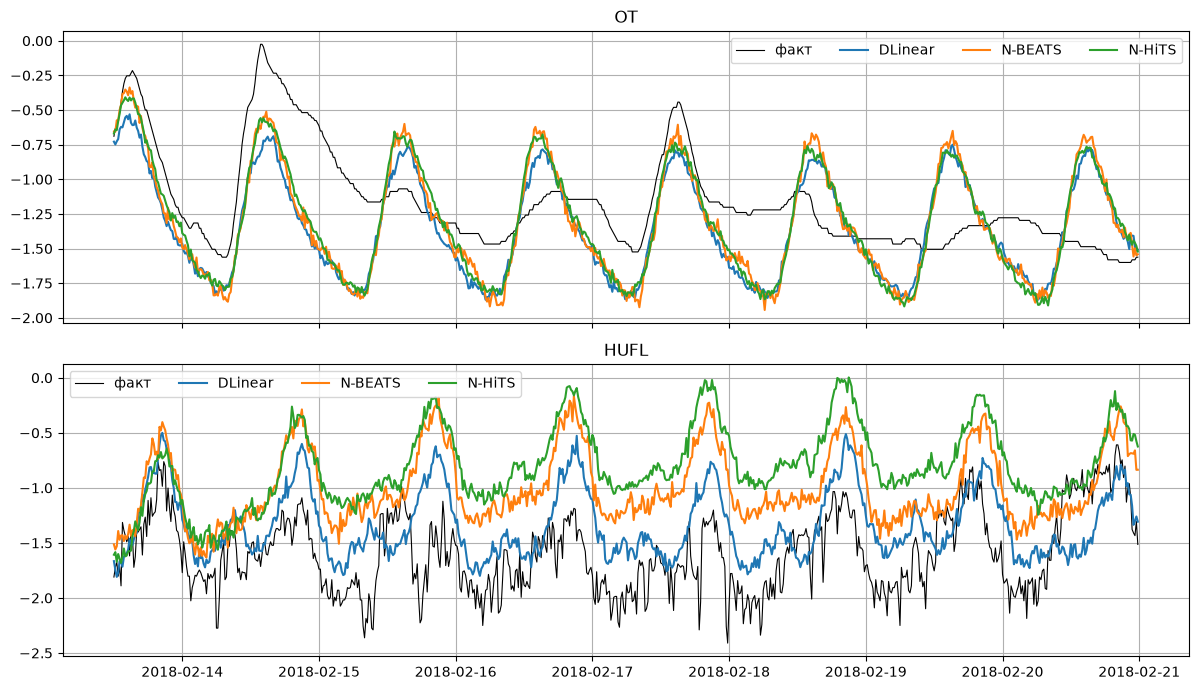

In [13]:
cutoff_last = cv_720["cutoff"].max()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, uid in zip(axes, ["OT", "HUFL"]):
    fc = cv_720[(cv_720["unique_id"] == uid) & (cv_720["cutoff"] == cutoff_last)]
    ax.plot(fc["ds"], fc["y"], color="black", lw=0.8, label="факт")
    for col in ["DLinear", "N-BEATS", "N-HiTS"]:
        ax.plot(fc["ds"], fc[col], label=col)
    ax.set_title(uid)
    ax.legend(ncol=4)
fig.tight_layout()

Что видно:
- **Все нейросети обходят seasonal naive**, а N-BEATS и оба варианта N-HiTS — ещё и DLinear, особенно по MSE.
- **N-HiTS не хуже N-BEATS при заметно меньшем числе параметров**; `24-12-1` — самый лёгкий из глубоких
  вариантов и при этом лучший. Время в таблице — грубая оценка: оно зависит от загрузки машины, и на CPU
  выигрыша N-HiTS во времени может не быть вовсе. Основная часть вычислений — скрытые слои 512×512,
  одинаковые у обеих моделей; разница сильнее проявляется на GPU и на длинных горизонтах.
- **Разница между моделями — в третьем знаке.** На пяти окнах и одном сиде это близко к шуму; порядок
  N-HiTS / N-BEATS / DLinear надо проверять на нескольких сидах (раздел 5).
- Ошибку на таком горизонте во многом определяет не форма суточного цикла, а сдвиги уровня (на HUFL все прогнозы
  весь отрезок выше факта), которые по истории предсказать нельзя.

В статье (табл. 1) выигрыш N-HiTS у N-BEATS на ETTm2 небольшой и **сокращается** с горизонтом: по MSE
0.176 против 0.184 (≈4%) при `h=96` и 0.401 против 0.411 (≈2%) при `h=720`, по MAE ≈3% на обоих горизонтах.
Сильный рост выигрыша с горизонтом там показан на других данных: на курсах валют (Exchange) по MSE
0.092 против 0.098 (≈6%) при `h=96` и 0.798 против 1.108 (≈28%) при `h=720`.
Поэтому честная формулировка для ETTm2: N-HiTS — **та же точность дешевле**, а не «намного точнее».

Что ещё стоит знать о цифрах статьи:
- **Наши ошибки выше, чем в статье** (MAE N-HiTS на `h=720` в табл. 1 — 0.413). Протоколы разные: в статье
  окно $L = 5H = 3600$, 1000 шагов с batch 256, подбор гиперпараметров по валидации (20 итераций HYPEROPT),
  а тест — последние 20% ряда со скользящим окном. У нас всего 5 окон в самом конце ряда, со сдвигами уровня.
  Сравнивать абсолютные числа нельзя, только порядок моделей.
- **Сид подбирался как гиперпараметр** (табл. A3: «чтобы уйти от неудачных локальных минимумов»), а метрики
  усреднены по восьми запускам. Разброс между запусками в статье — 2.9% от MSE и 1.75% от MAE (прил. E).
  Это сопоставимо с выигрышем у N-BEATS на ETTm2.
- **Обе идеи нужны вместе.** Абляция (табл. 2, среднее по пяти датасетам, `h=720`): MAE полного N-HiTS 0.439,
  только интерполяция — 0.450, только пулинг — 0.454, ни того ни другого — 0.468, интерпретируемый N-BEATS — 0.597.
  Базисы тренда и сезонности на длинном горизонте мешают сильнее всего.
- **Скорость.** На ETTm2 N-HiTS в 1.26 раза быстрее N-BEATS и использует 54% его параметров, а относительно
  Autoformer быстрее в 45 раз (раздел 4 статьи). По точности одномерная модель, которая видит только
  историю своего ряда, в среднем обошла лучший из многомерных трансформеров на 14% по MAE и на 16% по MSE.
  Авторы сами ставят вопрос, умеют ли эти трансформеры вообще пользоваться связями между рядами.

**Сколько учить — тоже гиперпараметр.** Здесь `max_steps=300`. С 1000 шагов N-BEATS и N-HiTS переобучаются:
на `h=720` MAE N-BEATS вырастает до 0.66 — хуже seasonal naive, и вывод «глубокие модели не нужны» был бы
артефактом обучения, а не свойством архитектуры. DLinear с его миллионом весов от числа шагов почти не зависит.

## 3. Разложение прогноза N-HiTS по частотам

Как и у N-BEATS, `decompose` возвращает вклад каждого стека: уровень (последнее значение окна), затем три
стека от грубого к детальному. Та же тонкость со `scaler_type="standard"`: каждый вклад возвращается
в шкалу ряда с прибавленным средним окна, поэтому вычитаем его. Сверяем сумму с прогнозом из `cross_validation`
на последнем отрезке ряда `OT`.

Берём N-HiTS `24-12-1`: у его стеков 30, 60 и 720 узлов, разделение по частотам видно лучше всего.

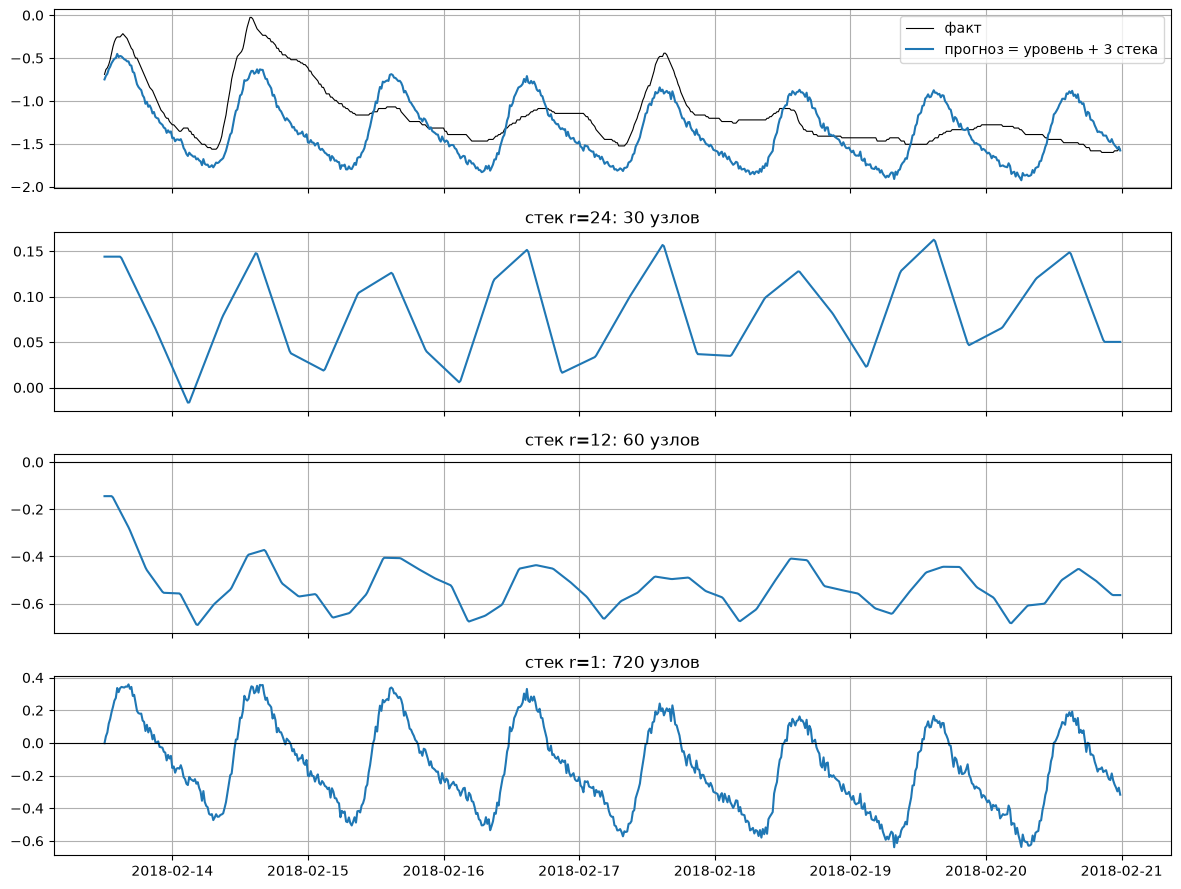

In [14]:
model = fitted["N-HiTS 24-12-1"].models[0]
model.set_test_size(0)  # после cross_validation модель помнит размер теста; прогнозируем только от конца истории
hist = Y_df[(Y_df["unique_id"] == "OT") & (Y_df["ds"] <= cutoff_last)]
dataset, *_ = TimeSeriesDataset.from_df(hist)
blocks = model.decompose(dataset=dataset)[0]  # (1 + 3 стека, H)

window_mean = hist["y"].to_numpy()[-L:].mean()
level, stacks = blocks[0], blocks[1:] - window_mean
fc = cv_720[(cv_720["unique_id"] == "OT") & (cv_720["cutoff"] == cutoff_last)]
assert np.allclose(level + stacks.sum(axis=0), fc["N-HiTS 24-12-1"], atol=1e-3), "разложение не сходится с прогнозом"

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(fc["ds"], fc["y"], color="black", lw=0.8, label="факт")
axes[0].plot(fc["ds"], fc["N-HiTS 24-12-1"], label="прогноз = уровень + 3 стека")
axes[0].legend()
for ax, s, r in zip(axes[1:], stacks, DOWN):
    ax.plot(fc["ds"], s)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"стек r={r}: {H // r} узлов")
fig.tight_layout()

- Стек с 30 узлами (`r=24`) рисует суточный цикл ломаной линией — грубо, но форма уже видна.
- Стек с 60 узлами здесь в основном сдвигает уровень вниз, добавляя небольшие колебания.
- Последний стек (`r=1`, все 720 точек) тоже рисует суточный цикл, причём с наибольшей амплитудой, плюс
  мелкий шум.

Разделение по частотам получилось **нестрогим**: узлы ограничивают только самый грубый стек, а стеку с 720 узлами
ничто не мешает нарисовать и медленную, и быструю составляющую. Разложение N-HiTS — одно из многих возможных,
сеть не обязана раскладывать «красиво». Чтобы части были содержательными, нужны ограничения посильнее — как
базисы тренда и сезонности у интерпретируемого N-BEATS.

Сравните с картинками статьи (рис. 5 и прил. G, рис. 4: тот же ETTm2, `h=720`). Там с линейной интерполяцией
первый стек рисует почти прямую, второй — суточный цикл, а третий близок к нулю. Без иерархической
интерполяции все три стека рисуют похожие зашумлённые копии ряда, и разложение теряет смысл. У нас картинка
промежуточная. Возможные причины: обучение короче (300 шагов против 1000), окно короче ($L = H$ против $5H$),
гиперпараметры не подбирались. Красивое разложение в статье — показательный пример, а не гарантия.

## 4. Итоговое сравнение: сутки вперёд

Возвращаемся к постановке 11.1: `h=96`, `input_size=336`, те же 5 окон. Все модели семинара на одних и тех же
окнах, каждая нейросеть — с **тремя сидами**: в таблице среднее и разброс.

Одинаковый `input_size` для всех — удобное, но не нейтральное условие: одни архитектуры лучше используют
длинную историю, чем другие. Честное сравнение подбирает `L` для каждой модели отдельно.

In [15]:
H_DAY, L_DAY, SEEDS = 96, 336, [1, 2, 3]
common_day = {**common, "h": H_DAY, "input_size": L_DAY}
architectures = {"DLinear": DLinear, "N-BEATS": NBEATS, "N-HiTS": NHITS}

cv_day = StatsForecast(models=[SeasonalNaive(96)], freq="15min").cross_validation(
    df=Y_df, h=H_DAY, n_windows=N_WINDOWS, step_size=H_DAY
)
train_time = {}
for name, cls in architectures.items():
    nf = NeuralForecast(
        models=[cls(alias=f"{name} seed={s}", **{**common_day, "random_seed": s}) for s in SEEDS], freq="15min"
    )
    start = time.time()
    cv = nf.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H_DAY)
    train_time[name] = (time.time() - start) / len(SEEDS)
    cv_day = cv_day.merge(cv.drop(columns="y"), on=["unique_id", "ds", "cutoff"])

by_seed = score(cv_day)
by_seed.index = by_seed.index.str.replace(r" seed=\d+", "", regex=True)
summary = by_seed.groupby(level=0).agg(["mean", "std"]).round(3)
summary["время на модель, с"] = pd.Series(train_time).round(0)
summary.sort_values(("mae", "mean"))

metric           mae           mse        время на модель, с
                mean    std   mean    std                   
N-HiTS         0.177  0.007  0.066  0.006               14.0
DLinear        0.178  0.002  0.065  0.001                3.0
N-BEATS        0.178  0.007  0.067  0.005                9.0
SeasonalNaive  0.207    NaN  0.109    NaN                NaN

Прогнозы на последних сутках (сид 1):

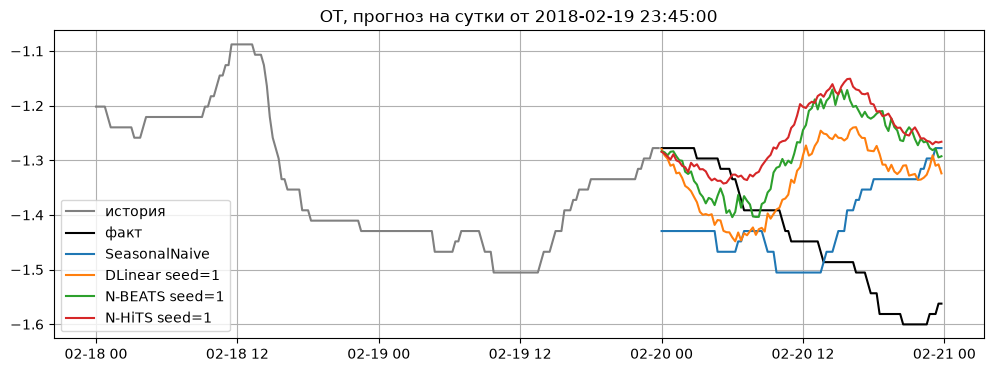

In [16]:
uid = "OT"
cutoff_day = cv_day["cutoff"].max()
hist = Y_df[(Y_df["unique_id"] == uid) & (Y_df["ds"] <= cutoff_day)].tail(2 * H_DAY)
fc = cv_day[(cv_day["unique_id"] == uid) & (cv_day["cutoff"] == cutoff_day)]
plt.plot(hist["ds"], hist["y"], color="grey", label="история")
plt.plot(fc["ds"], fc["y"], color="black", label="факт")
for col in ["SeasonalNaive", "DLinear seed=1", "N-BEATS seed=1", "N-HiTS seed=1"]:
    plt.plot(fc["ds"], fc[col], label=col)
plt.title(f"{uid}, прогноз на сутки от {cutoff_day}")
plt.legend();

Итог на ETTm2: все три нейросети уверенно обходят seasonal naive (MAE ≈0.18 против 0.21), а между собой
на сутках вперёд **не различаются**: разница средних меньше разброса по сидам. DLinear при этом в 3 раза
быстрее и устойчивее к сиду. На неделю вперёд (раздел 2) глубокие модели немного впереди.
Выбор архитектуры определяется не столько точностью на бенчмарке, сколько тем, что ещё нужно от модели:

| нужно | модель |
|---|---|
| быстрый сильный бейзлайн | DLinear |
| прогноз, разложенный на тренд и сезонность | N-BEATS interpretable |
| длинный горизонт при умеренной стоимости | N-HiTS |

## 5. Для самостоятельного изучения

- **Интерполяция.** `interpolation_mode="nearest"` / `"linear"` / `"cubic"`: как меняется вид прогноза
  на `h=720`.
- **Прореживание.** Другие `n_freq_downsample` (`[168, 24, 1]`, `[1, 1, 1]` — это почти N-BEATS) и
  `n_pool_kernel_size`.
- **Порядок стеков.** `n_freq_downsample=[1, 12, 24]`, `n_pool_kernel_size=[1, 8, 16]` — bottom-up из
  табл. A8 статьи: становится ли хуже и как меняется разложение из раздела 3?
- **Пулинг.** `pooling_mode="AvgPool1d"` против `"MaxPool1d"` на `h=720`.
- **Длина окна.** `input_size` = 720 / 1440 / 3600 (как в статье, $5H$) для N-HiTS и DLinear на `h=720`.
- **Сиды на `h=720`.** Повторите сравнение из раздела 2 с тремя сидами — устойчив ли порядок моделей?
- **Число шагов.** Повторите раздел 2 с `max_steps=1000`. Вместо подбора руками — ранняя остановка:
  `val_check_steps=100, early_stop_patience_steps=3` в модели и `val_size` в `cross_validation`.
- **`AutoNHITS`** — подбор гиперпараметров по валидационной части (бэкенд `ray` или `optuna`):

In [17]:
import optuna
from neuralforecast.auto import AutoNHITS

optuna.logging.set_verbosity(optuna.logging.WARNING)

auto_config = lambda trial: {
    "input_size": L_DAY,
    "max_steps": MAX_STEPS,
    "learning_rate": trial.suggest_categorical("learning_rate", [1e-3, 3e-3]),
    "n_pool_kernel_size": trial.suggest_categorical("n_pool_kernel_size", [[2, 2, 1], [8, 4, 1]]),
    "n_freq_downsample": trial.suggest_categorical("n_freq_downsample", [[4, 2, 1], [12, 4, 1]]),
    "scaler_type": "standard",
    "random_seed": SEED,
    **TRAINER_KW,
}
auto = AutoNHITS(h=H_DAY, config=auto_config, backend="optuna", num_samples=4)
nf_auto = NeuralForecast(models=[auto], freq="15min")
cv_auto = nf_auto.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H_DAY, val_size=10 * H_DAY)
print("лучшие параметры:", nf_auto.models[0].results.best_trial.params)
score(cv_day[["unique_id", "ds", "cutoff", "y", "N-HiTS seed=1"]].merge(cv_auto.drop(columns="y")))

лучшие параметры: {'learning_rate': 0.001, 'n_pool_kernel_size': [2, 2, 1], 'n_freq_downsample': [12, 4, 1]}


metric,mae,mse
N-HiTS seed=1,0.169,0.060
AutoNHITS,0.171,0.062


Подбор не дал выигрыша: параметры по умолчанию на ETTm2 уже хороши, а четыре попытки и одна валидационная
часть — слишком мало, чтобы найти что-то лучше. Кроме того, `AutoNHITS` учится без последних `val_size` точек.
Автоподбор окупается на новых данных, где разумных значений по умолчанию нет.

В статье (прил. I, рис. 6) подбор окупался, но постепенно: выигрыш N-HiTS у Autoformer по MSE рос от ≈17%
с одной случайной конфигурацией до ≈25% после 20 итераций HYPEROPT. Обучение N-HiTS дёшево, поэтому
даже 20 итераций (30.5 ч GPU на все эксперименты) обходятся дешевле одного прогона Autoformer (92.6 ч, табл. A10).

## 6. Итоги семинара

1. **Ряд → обучающая выборка.** Окна `input_size` → `h`, случайные батчи, глобальная модель на всех рядах,
   нормализация окна, разбиение по времени и обязательная планка seasonal naive.
2. **Прогноз можно разложить на понятные части.** DLinear — фиксированным скользящим средним,
   N-BEATS — на тренд и сезонность через базисы, N-HiTS — на частотные диапазоны.
3. **Многомасштабность для длинного горизонта.** Пулинг входа и прогноз по узлам делают модель дешевле
   без потери точности: гладкость прогноза задана архитектурой, а не выучивается из данных.
4. **Сравнение моделей — это эксперимент.** Несколько окон, несколько сидов, одинаковые условия;
   разница в третьем знаке на одном запуске ничего не значит.

Все прогнозы до сих пор были **точечными** и строились **только по истории ряда**. Внешние факторы
и вероятностный прогноз — следующий семинар.